In [14]:
# input

# ZIP       CITY
# 60616 Chicago
# …. x999
# 60616 Chicago
# 60616 NY


# ZIP       CITY
# 60616 Chicago  x 500
# 60616 NY           x 500


# x1 y11b
# x1 y12
# x2 y21
# x2 y22
# ....

# x1000 y1000_1
# x1000 y1000_2



# x1 y1\_1
# ...
# x1 y1\_1000
# x2 y2
# ....

# x1000 y1000
# x1001 y1001

# a good measure should:

# 1st: high
# 2nd: middle
# 3rd: very low?
# 4th: 

# 1>2>4>3?

In [15]:
import pandas as pd
from collections import defaultdict
import math
import random
import string
import os
from typing import Dict, Tuple
import sys

import pandas as pd
import numpy as np
# for Jupyter notebooks: add the path of 'code' to allow importing module
sys.path.append(os.path.join(os.getcwd(), ".."))
# Set to display all rows and columns
pd.set_option('display.max_rows', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.float_format', '{:.6f}'.format)
from measures_generalized import measures_dict
from hypothesis_testing import chi_square_test


In [16]:
lhs_num = 1
rhs_num = 1
row_cnt = 1000



In [17]:
def gen_random_text_str(length):
    characters = string.ascii_letters  
    random_str = ''.join(random.choice(characters) for _ in range(length))
    return random_str

def gen_random_number(length):
    return int(''.join(random.choice("0123456789") for _ in range(length)))

In [18]:
dfs = []

In [20]:
def gen_syntactic_data(
    col_names = [],
    row_cnt = 1000,
    lhs_fractions = [],
    rhs_fractions = [],
    number_of_groups=1,
    df_name=None,
    
):
    
    # df = pd.DataFrame(columns=list(cols.keys()))
    rows = []
    used_lhs_vals = set()
    used_rhs_vals = set()
    for ng in range(0, number_of_groups):
        cur_rows = []
        cur_start = 0
        for frl in lhs_fractions:
            group_total_size = math.floor(row_cnt*frl)
            lhv = gen_random_number(5)
            while(lhv in used_lhs_vals):
                lhv = gen_random_number(5)
            used_lhs_vals.add(lhv)
            for j in range(cur_start, cur_start+group_total_size):
                cur_rows.append([lhv])
            cur_start+=group_total_size
        # print(f"len cur_rows = {len(cur_rows)}")
        cur_start = 0
        for i in range(len(rhs_fractions)):
            group_total_size = math.floor(row_cnt*lhs_fractions[i])
            # print(group_total_size)
            for g_r_ratio in rhs_fractions[i]:
                rhv = gen_random_text_str(5)
                while(rhv in used_rhs_vals):
                    rhv = gen_random_text_str(5)
                used_rhs_vals.add(rhv)
                # print(f"from {cur_start} to {cur_start+math.floor(group_total_size*g_r_ratio)}")
                for j in range(cur_start, cur_start+math.floor(group_total_size*g_r_ratio)):
                    cur_rows[j].append(rhv)
                cur_start += math.floor(group_total_size*g_r_ratio)
        rows.extend(cur_rows)
    df = pd.DataFrame(rows, columns=col_names)
    df['group_size'] = number_of_groups
    df['df_name'] = df_name
    return df 

In [21]:
for g in [1,2,4,8,16]:
    fraction_ratios_lhs_1999_1 = [1]
    fraction_ratios_rhs_1999_1 = [[0.9995,0.0005]]
    df_1999_vs_1 = gen_syntactic_data(col_names =['x','y'], row_cnt=2000, 
                                      lhs_fractions=fraction_ratios_lhs_1999_1, 
                                      rhs_fractions=fraction_ratios_rhs_1999_1,
                                     number_of_groups=g,
                                     df_name='df_1999_vs_1')
    dfs.append(df_1999_vs_1)
    fraction_ratios_lhs_1000_1000 = [1]
    fraction_ratios_rhs_1000_1000 = [[0.5,0.5]]
    df_1000_vs_1000 = gen_syntactic_data(col_names =['x','y'], row_cnt=2000, 
                                         lhs_fractions=fraction_ratios_lhs_1000_1000, 
                                         rhs_fractions=fraction_ratios_rhs_1000_1000,
                                     number_of_groups=g,
                                     df_name='df_1000_vs_1000')
    dfs.append(df_1000_vs_1000)
    fraction_ratios_lhs_2_per_group = [0.001]*1000
    fraction_ratios_rhs_2_per_group = [[0.5,0.5]]*1000
    df_2_per_group = gen_syntactic_data(col_names =['x','y'], row_cnt=2000, 
                                        lhs_fractions=fraction_ratios_lhs_2_per_group, 
                                        rhs_fractions=fraction_ratios_rhs_2_per_group,
                                     number_of_groups=g,
                                     df_name='df_2_per_group')
    dfs.append(df_2_per_group)
    fraction_ratios_lhs_half_and_distinct = [0.5] + [0.0005]*1000
    fraction_ratios_rhs_half_and_distinct =  [[0.001]*1000] + [[1] for i in range(0,1000)]
    df_half_and_distinct = gen_syntactic_data(col_names =['x','y'], row_cnt=2000, 
                                              lhs_fractions=fraction_ratios_lhs_half_and_distinct,
                                              rhs_fractions=fraction_ratios_rhs_half_and_distinct,
                                     number_of_groups=g,
                                     df_name='df_half_and_distinct')
    dfs.append(df_half_and_distinct)


In [22]:
len(dfs)

20

In [23]:
df = pd.concat(dfs)

In [24]:
df.shape

(248000, 4)

In [13]:
measures_to_show = ['rho', 'g1', 'g1_prime', 'g2',
       'g3', 'g3_prime']

In [25]:
grouped_df = df.groupby(['df_name','group_size'])

In [28]:
res = []

In [32]:
for (df_name, dgroup_size), group_data in grouped_df:
    print(df_name)
    print(dgroup_size)
    print(group_data.shape)
    print('\n')
    for m in measures_to_show:
        mres = {'df':df_name, 'measure':m, 'group_size':dgroup_size, 'val': measures_dict[m](df=group_data, 
                                                             lhs=['x'],
                                                             rhs=['y'])}
        res.append(mres)

df_1000_vs_1000
1
(2000, 4)


df_1000_vs_1000
2
(4000, 4)


df_1000_vs_1000
4
(8000, 4)


df_1000_vs_1000
8
(16000, 4)


df_1000_vs_1000
16
(32000, 4)


df_1999_vs_1
1
(2000, 4)


df_1999_vs_1
2
(4000, 4)


df_1999_vs_1
4
(8000, 4)


df_1999_vs_1
8
(16000, 4)


df_1999_vs_1
16
(32000, 4)


df_2_per_group
1
(2000, 4)


df_2_per_group
2
(4000, 4)


df_2_per_group
4
(8000, 4)


df_2_per_group
8
(16000, 4)


df_2_per_group
16
(32000, 4)


df_half_and_distinct
1
(2000, 4)


df_half_and_distinct
2
(4000, 4)


df_half_and_distinct
4
(8000, 4)


df_half_and_distinct
8
(16000, 4)


df_half_and_distinct
16
(32000, 4)




In [33]:
df_res = pd.DataFrame(res)

In [34]:
# df_res['measure'].unique()

In [18]:
# df = df_res[df_res['measure'].isin(measures_to_show)]

In [35]:
df_res.sort_values(by=['measure','df'])

,df,measure,group_size,val
1,df_1000_vs_1000,g1,1,0.500000
7,df_1000_vs_1000,g1,2,0.750000
13,df_1000_vs_1000,g1,4,0.875000
19,df_1000_vs_1000,g1,8,0.937500
25,df_1000_vs_1000,g1,16,0.968750
31,df_1999_vs_1,g1,1,0.999000
37,df_1999_vs_1,g1,2,0.999500
43,df_1999_vs_1,g1,4,0.999750
49,df_1999_vs_1,g1,8,0.999875
55,df_1999_vs_1,g1,16,0.999938


In [36]:
import matplotlib.pyplot as plt


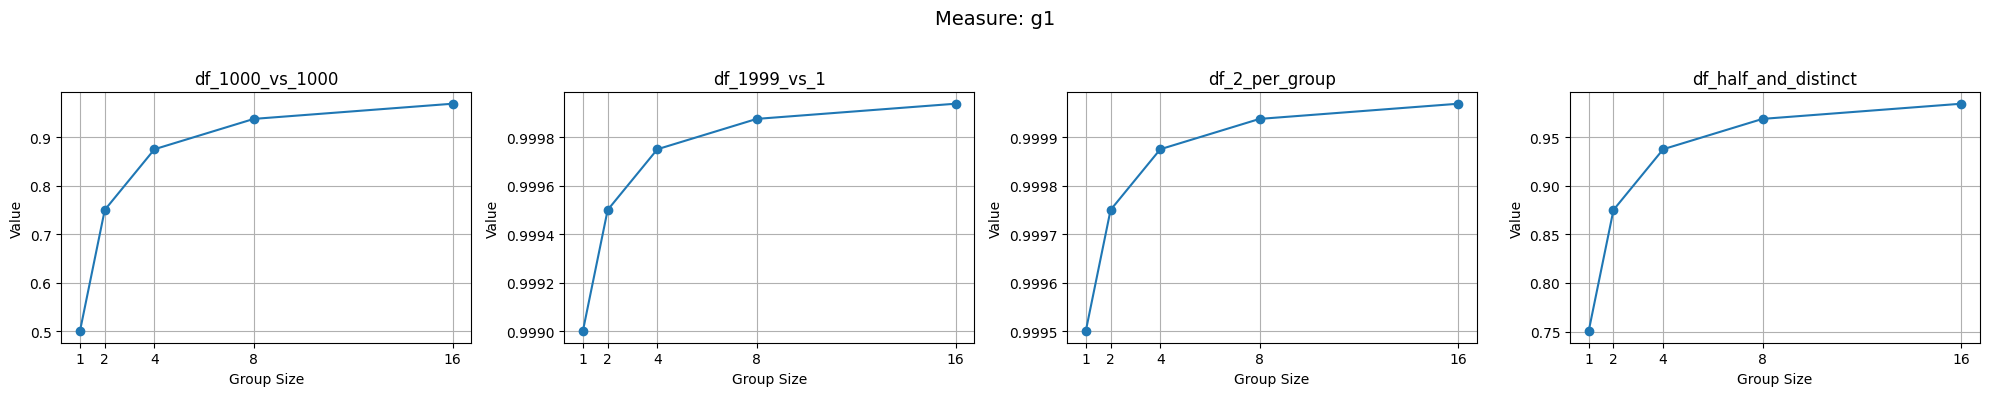

Saved plot as measure_g1.png


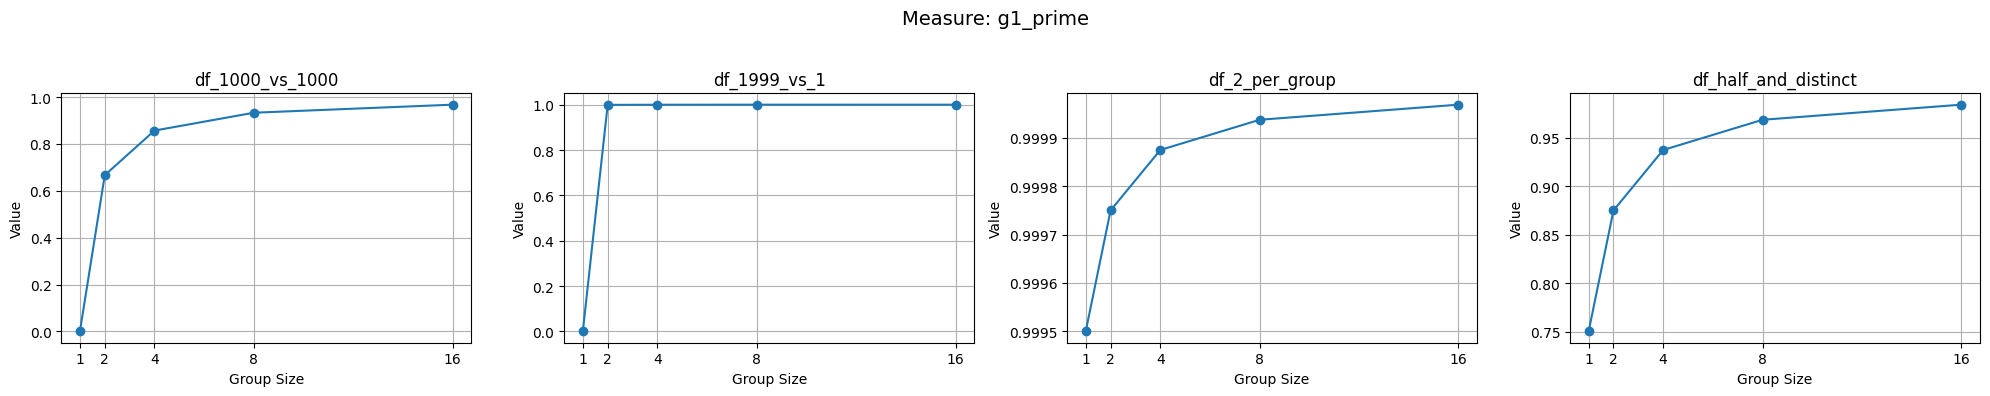

Saved plot as measure_g1_prime.png


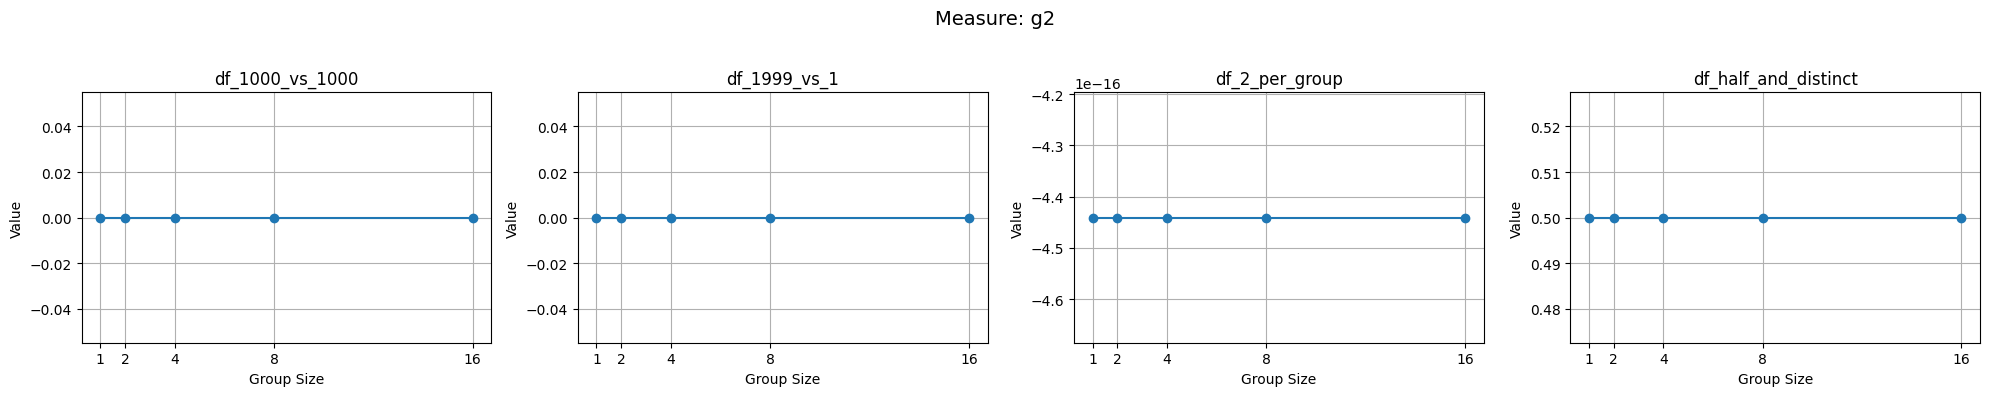

Saved plot as measure_g2.png


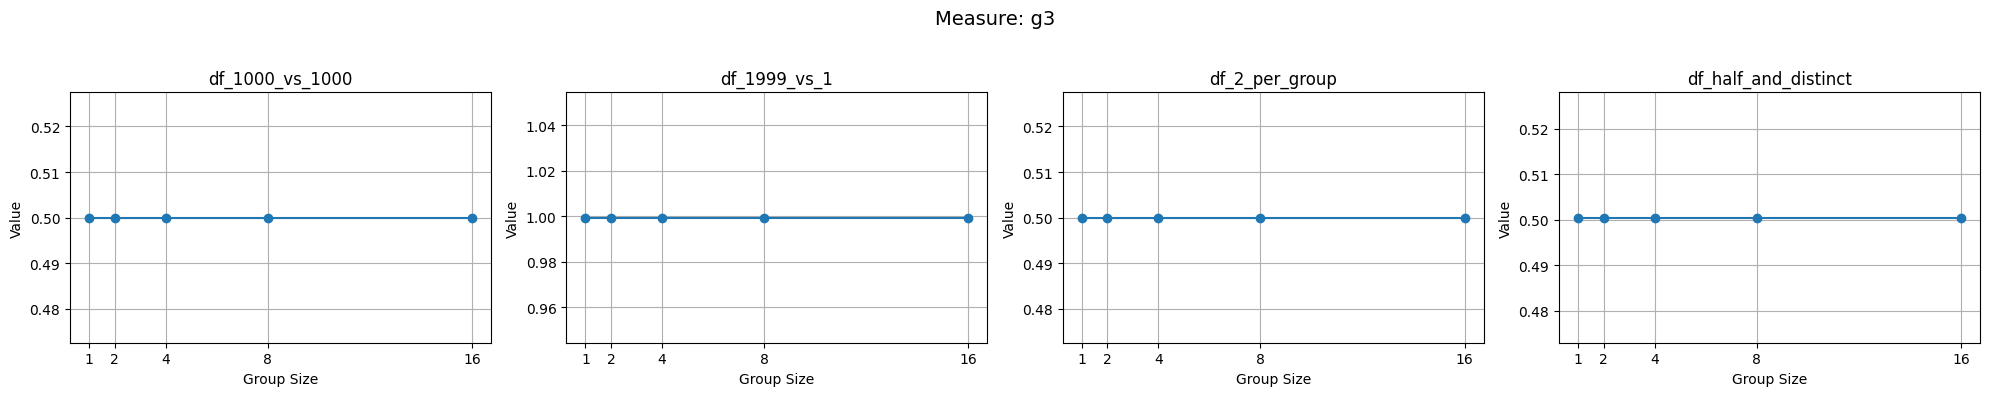

Saved plot as measure_g3.png


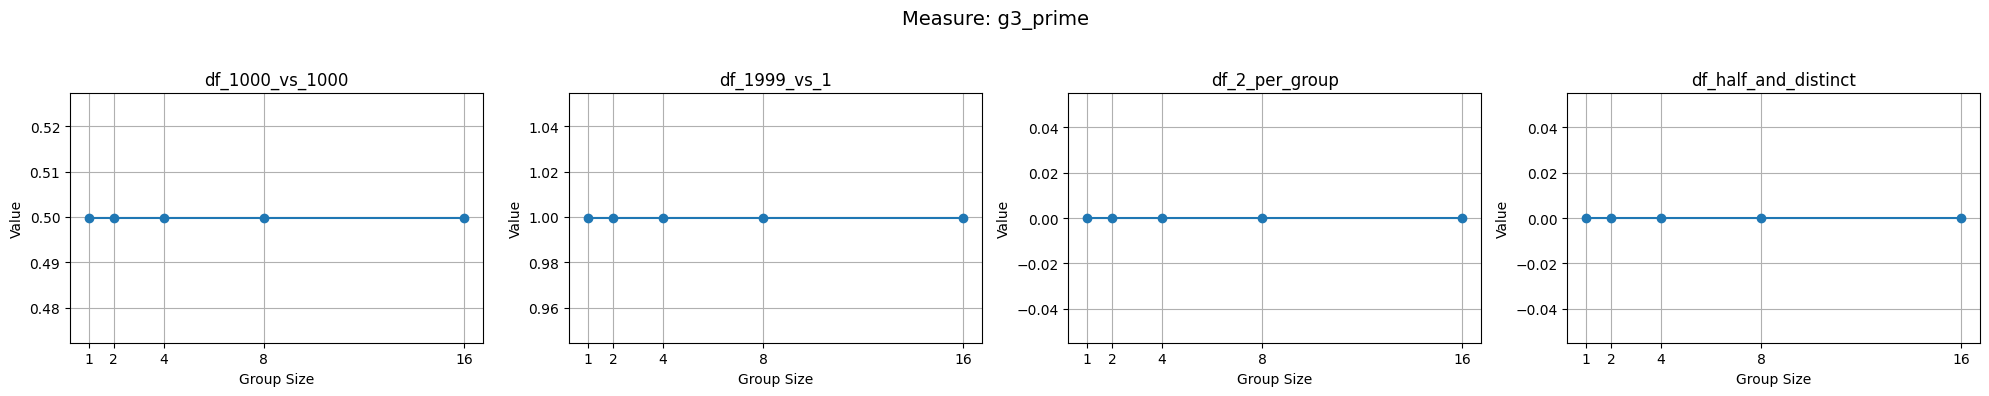

Saved plot as measure_g3_prime.png


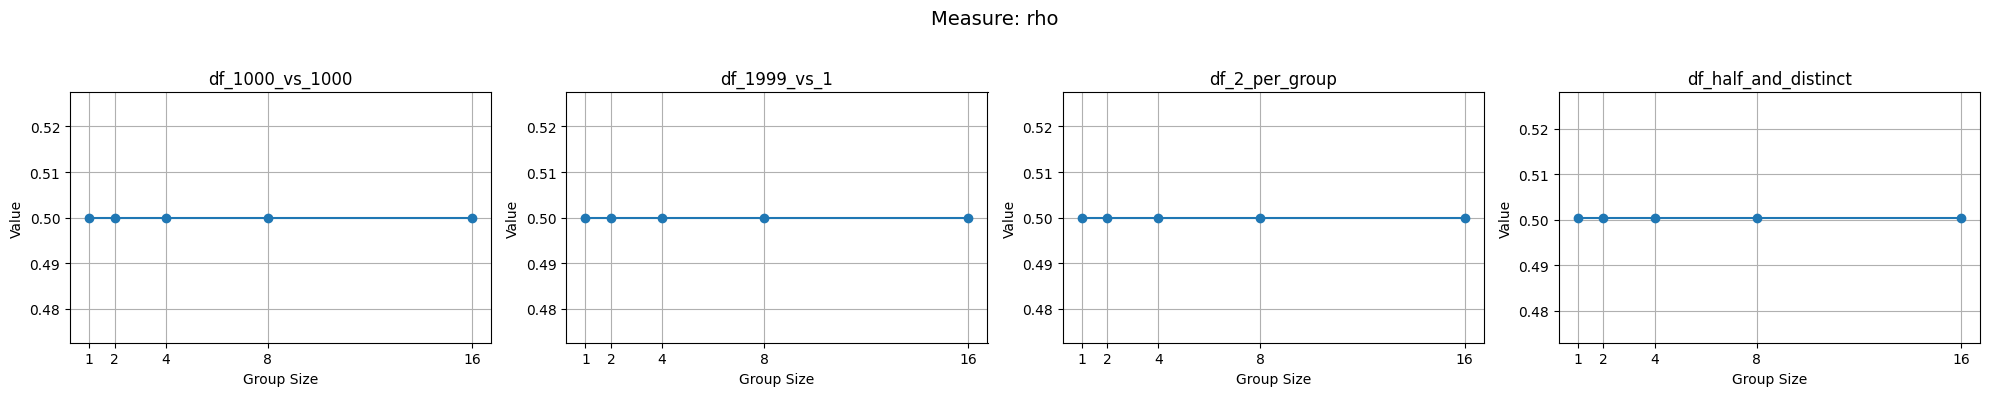

Saved plot as measure_rho.png


In [39]:
# Group by measure and then by df
measure_grouped = df_res.groupby('measure')

for measure, measure_data in measure_grouped:
    unique_dfs = measure_data['df'].unique()
    fig, axs = plt.subplots(1, len(unique_dfs), figsize=(5 * len(unique_dfs), 4))
    fig.suptitle(f"Measure: {measure}", fontsize=14)
    
    # Ensure axs is iterable even for a single subplot
    if len(unique_dfs) == 1:
        axs = [axs]
    
    for ax, (df_name, group_data) in zip(axs, measure_data.groupby('df')):
        ax.plot(group_data['group_size'], group_data['val'], marker='o')
        ax.set_title(df_name)
        ax.set_xlabel('Group Size')
        ax.set_ylabel('Value')
        ax.set_xticks(group_data['group_size'])  # Ensure ticks are integers
        ax.grid(True)
    
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    
    # Save the figure as a PNG file
    filename = f"measure_{measure}.png"
    plt.show()
    print(f"Saved plot as {filename}")
    
    # Close the figure to free up memory
    plt.close(fig)

In [27]:
df_names_part1

array(['df-1999-1', 'df-1000-1000', 'df_2_per_group',
       'df_half_same_half_distinct'], dtype=object)

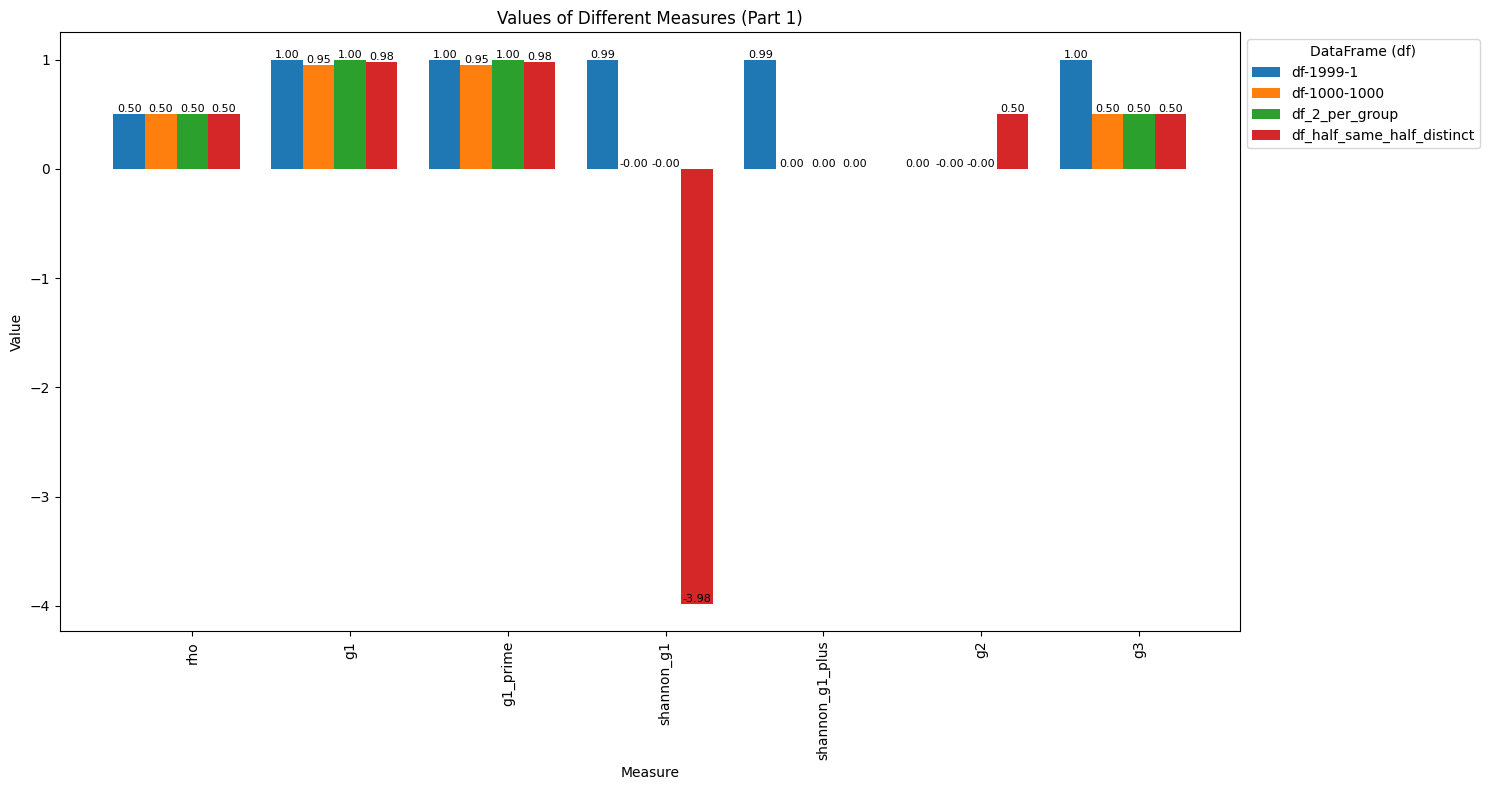

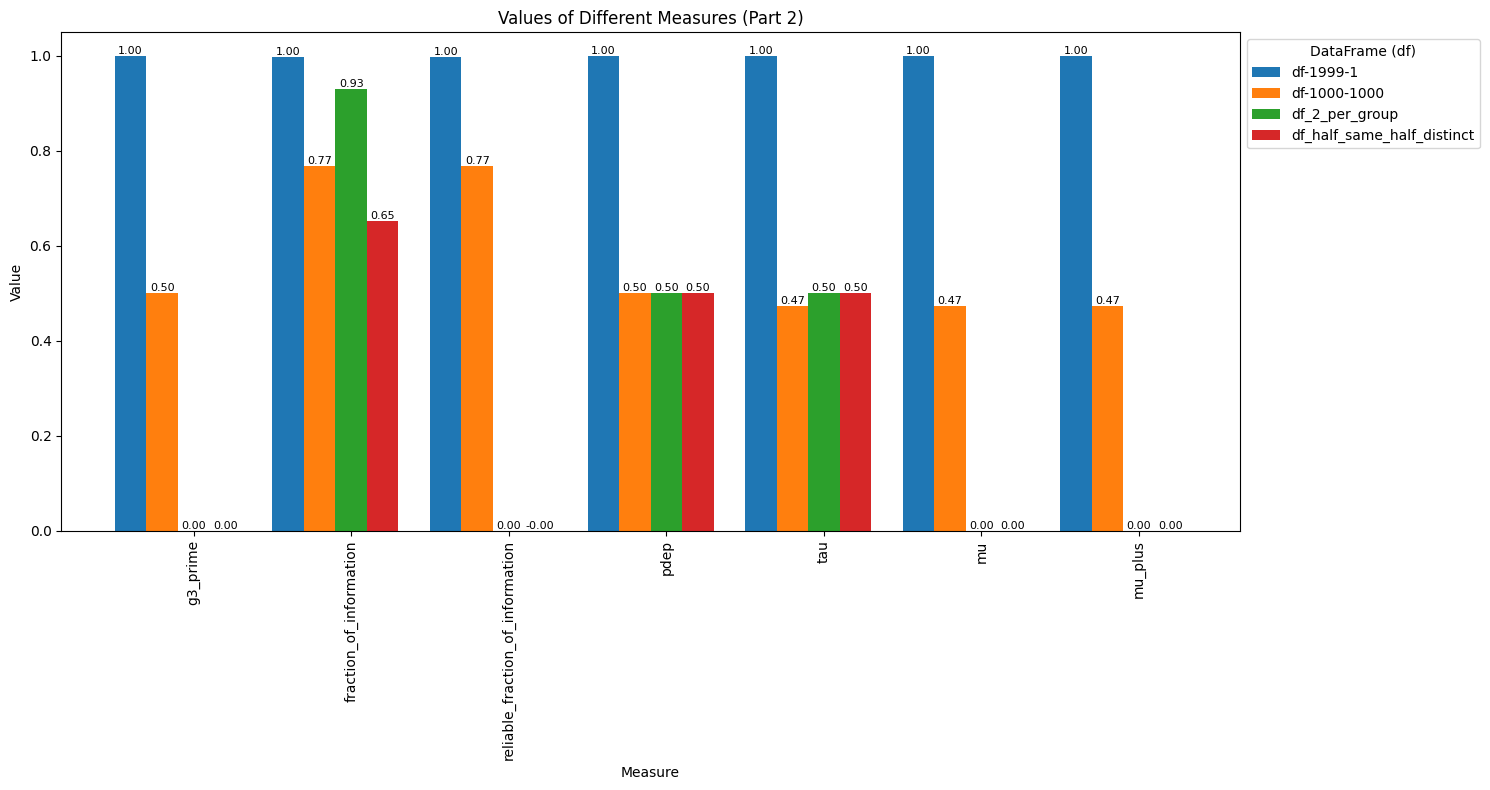

In [29]:

measures_part1 = df['measure'].unique()[:7]
measures_part2 = df['measure'].unique()[7:]

def plot_subset(measure_subset, title):
    plt.figure(figsize=(15, 8))
    bar_width = 0.2  
    df_names = df['df'].unique()  
    x_positions = range(len(measure_subset))  
    color_palette = sns.color_palette("tab10", len(df_names))
    
    for i, df_name in enumerate(df_names):
        subset = df[(df['df'] == df_name) & (df['measure'].isin(measure_subset))]
        x = [j + i * bar_width for j in x_positions] 
        bars = plt.bar(x, subset['val'], width=bar_width, color=color_palette[i], label=df_name)
        
        # Add values on top of each bar
        for bar in bars:
            yval = bar.get_height()
            plt.text(bar.get_x() + bar.get_width() / 2, yval, f'{yval:.2f}', ha='center', va='bottom', fontsize=8)

    # Customizing the plot
    plt.xlabel('Measure')
    plt.ylabel('Value')
    plt.title(title)
    plt.legend(title="DataFrame (df)", loc='upper left', bbox_to_anchor=(1, 1))
    plt.xticks([r + bar_width * (len(df_names) / 2) for r in x_positions], measure_subset, rotation=90)
    plt.tight_layout()
    plt.show()

plot_subset(measures_part1, "Values of Different Measures (Part 1)")

plot_subset(measures_part2, "Values of Different Measures (Part 2)")

In [30]:
# # Adjusting the plot with more distinguishable colors for each DataFrame (df) bar

# import matplotlib.pyplot as plt
# import seaborn as sns

# plt.figure(figsize=(15, 8))

# # Parameters for bar plot
# unique_measures = df['measure'].unique()
# df_names = df['df'].unique()
# bar_width = 0.2  # Width of each bar in a group
# x_positions = range(len(unique_measures))  # Positions for each group on the x-axis
# color_palette = sns.color_palette("tab10", len(df['df'].unique()))


# # Plot each DataFrame (df) as a bar within each measure group using more distinguishable colors
# for i, df_name in enumerate(df_names):
#     subset = df[df['df'] == df_name]
#     x = [j + i * bar_width for j in x_positions]  # Shift each df's bars within a group
#     bars = plt.bar(x, subset['val'], width=bar_width, color=color_palette[i], label=df_name)
    
#     # Add values on top of each bar
#     for bar in bars:
#         yval = bar.get_height()
#         plt.text(bar.get_x() + bar.get_width() / 2, yval, f'{yval:.2f}', ha='center', va='bottom', fontsize=8)
        
# # Customizing the plot
# plt.xlabel('Measure')
# plt.ylabel('Value')
# plt.title('Values of Different Measures Across DataFrames')
# plt.legend(title="DataFrame (df)", loc='upper left', bbox_to_anchor=(1, 1))

# # X-axis setup
# plt.xticks([r + bar_width * (len(df_names) / 2) for r in x_positions], unique_measures, rotation=90)

# plt.tight_layout()
# plt.show()

In [31]:
dfs = {
    'df-1999-1':df_1999_vs_1,
    'df-1000-1000':df_1000_vs_1000,
    'df_2_per_group': df_2_per_group,
    'df_half_same_half_distinct': df_half_and_distinct
}

In [32]:
dfs['df-1999-1']

,x,y
0,79563,pbAxR
1,79563,pbAxR
2,79563,pbAxR
3,79563,pbAxR
4,79563,pbAxR
5,79563,pbAxR
6,79563,pbAxR
7,79563,pbAxR
8,79563,pbAxR
9,79563,pbAxR


In [33]:
dfs['df-1000-1000']

,x,y
0,50227,QnKks
1,50227,QnKks
2,50227,QnKks
3,50227,QnKks
4,50227,QnKks
5,50227,QnKks
6,50227,QnKks
7,50227,QnKks
8,50227,QnKks
9,50227,QnKks


In [34]:
len(list(dfs['df_2_per_group']['x'].unique()))

10000

In [35]:
len(list(dfs['df_2_per_group']['y'].unique()))

20000

In [36]:
len(dfs['df_half_same_half_distinct']['x'].unique())

10010

In [37]:
len(dfs['df_half_same_half_distinct']['y'].unique())

20000

In [38]:
len(dfs['df_half_same_half_distinct'])

20000

In [40]:
chi_square_test_res = {}

In [41]:
for k in dfs:
    chi_square_test_res[k] = {}
    res, table = chi_square_test(df=dfs[k], x='x', y='y')
    chi_square_test_res[k]['res'] = res 
    chi_square_test_res[k]['ctable'] = table
    print(f"df={k}, res={res.pvalue}")
    # display(table)
    # print("\n")
    # break

df=df-1999-1, res=0.0
df=df-1000-1000, res=0.0
df=df_2_per_group, res=0.30853313673034827
df=df_half_same_half_distinct, res=0.30844515077083595


In [45]:
chi_square_test_res['df-1999-1']['res']

Chi2ContingencyResult(statistic=np.float64(179999.99999999997), pvalue=np.float64(0.0), dof=171, expected_freq=array([[1.999e+02, 1.999e+02, 1.999e+02, 1.999e+02, 1.000e-01, 1.999e+02,
        1.000e-01, 1.000e-01, 1.999e+02, 1.999e+02, 1.000e-01, 1.999e+02,
        1.000e-01, 1.999e+02, 1.000e-01, 1.999e+02, 1.000e-01, 1.000e-01,
        1.000e-01, 1.000e-01],
       [1.999e+02, 1.999e+02, 1.999e+02, 1.999e+02, 1.000e-01, 1.999e+02,
        1.000e-01, 1.000e-01, 1.999e+02, 1.999e+02, 1.000e-01, 1.999e+02,
        1.000e-01, 1.999e+02, 1.000e-01, 1.999e+02, 1.000e-01, 1.000e-01,
        1.000e-01, 1.000e-01],
       [1.999e+02, 1.999e+02, 1.999e+02, 1.999e+02, 1.000e-01, 1.999e+02,
        1.000e-01, 1.000e-01, 1.999e+02, 1.999e+02, 1.000e-01, 1.999e+02,
        1.000e-01, 1.999e+02, 1.000e-01, 1.999e+02, 1.000e-01, 1.000e-01,
        1.000e-01, 1.000e-01],
       [1.999e+02, 1.999e+02, 1.999e+02, 1.999e+02, 1.000e-01, 1.999e+02,
        1.000e-01, 1.000e-01, 1.999e+02, 1.999e+02, 1.00

In [47]:
chi_square_test_res['df-1999-1']['ctable']

y,AQqxz,BLAdN,CVLQo,FayHV,HJBjY,HUMcB,JfoTw,KuPfT,QLGPH,RGMQb,enBAT,fHjSb,gUWnw,lspct,maaej,pbAxR,sLDKW,tRsvK,uwjuB,xqODJ
x,,,,,,,,,,,,,,,,,,,,
14208,0,0,0,1999,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
25136,0,0,0,0,0,0,0,0,1999,0,0,0,0,0,0,0,0,0,1,0
28158,0,0,0,0,0,0,1,0,0,0,0,0,0,1999,0,0,0,0,0,0
28850,0,0,0,0,0,0,0,0,0,0,0,1999,0,0,0,0,0,0,0,1
31823,0,1999,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0
39071,1999,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0
39296,0,0,1999,0,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0
39572,0,0,0,0,1,0,0,0,0,1999,0,0,0,0,0,0,0,0,0,0
69167,0,0,0,0,0,1999,0,0,0,0,0,0,0,0,1,0,0,0,0,0


In [48]:
chi_square_test_res['df-1000-1000']['res']

Chi2ContingencyResult(statistic=np.float64(180000.0), pvalue=np.float64(0.0), dof=171, expected_freq=array([[100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100.,
        100., 100., 100., 100., 100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100.,
        100., 100., 100., 100., 100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100.,
        100., 100., 100., 100., 100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100.,
        100., 100., 100., 100., 100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100.,
        100., 100., 100., 100., 100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100.,
        100., 100., 100., 100., 100., 100., 100., 100., 100.],
       [100., 100., 100., 100., 100., 100., 100., 100., 100., 100., 100.,
   

In [49]:
chi_square_test_res['df-1000-1000']['ctable']

y,BnAet,IrQXp,Jngnr,LzRZo,QnKks,SkFSq,TBWPW,bYXhP,fszoe,hDFNn,jDkuJ,kfJNO,lCqfb,nOFxp,ncRdz,pgBJU,rQklX,vLfVX,xfmLC,ypWrp
x,,,,,,,,,,,,,,,,,,,,
17792,0,0,1000,0,0,0,0,0,0,1000,0,0,0,0,0,0,0,0,0,0
22761,0,0,0,0,0,1000,0,0,0,0,0,1000,0,0,0,0,0,0,0,0
23756,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1000,1000,0
33155,0,1000,0,0,0,0,0,0,0,0,0,0,1000,0,0,0,0,0,0,0
43343,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1000,1000,0,0,0
49393,1000,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1000
50227,0,0,0,0,1000,0,0,0,0,0,1000,0,0,0,0,0,0,0,0,0
55918,0,0,0,1000,0,0,0,1000,0,0,0,0,0,0,0,0,0,0,0,0
59354,0,0,0,0,0,0,1000,0,1000,0,0,0,0,0,0,0,0,0,0,0
